# Global Prochlorococcus Gene Prevalence Estimates

The purpose of this notebook is to generate a global estimate of the prevalence of every
known gene family in the Prochlorococcus pangenome.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sqlite3

from gene_prevalence import BernoulliPrevalenceModel, combine_approx_var_likelihood
from matplotlib.patches import Wedge, Patch
from itertools import combinations

# instatiate random number generator with fixed seed for reproducibility
rng = np.random.default_rng(seed=9481)

# significance level for confidence intervals
ci_alpha = 0.05

In [2]:
# set aesthetic parameters

line_color = '#0F0A0A'    # dark

neutral_color = '#E0E0E0'

# thursday
accent_colors = ['#9B5DE5', '#FFAC69', '#00C9AE', '#FD3F92', '#0F0A0A', 
                 '#959AB1', '#FFDB66', '#63B9FF','#FFB1CA', '#4F1DD7']

style = {'axes.edgecolor': line_color,
         'axes.labelcolor': line_color,
         'text.color': line_color,
         'xtick.color': line_color,
         'ytick.color': line_color,
         'font.family': 'Helvetica',
         'font.Helvetica': ['Helvetica']}

palette = sns.color_palette(accent_colors)

sns.set_context('talk', rc={'lines.linewidth': 2})
sns.set_palette(palette)
sns.set_style('ticks', style)

plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['patch.linewidth'] = 0
plt.rcParams['patch.edgecolor'] = 'none'
plt.rcParams['savefig.dpi'] = 300

In [3]:
# import pro relative abundances by biome and clade (from GRUMP, processed by Yubin)

# directory paths
project_root = Path.cwd().resolve().parent
data_dir = project_root / "data" / "inputs"

# pro relative abundances by biome and clade
pro_rel_abund_df = pd.read_csv(data_dir / "Pro_Ecotype_Recipe_Rel_Abundance.csv")
pro_rel_abund_df['biome'] = pro_rel_abund_df['manual.bin'].str.split('_').str[0]
pro_rel_abund_df['depth_bin'] = pro_rel_abund_df['manual.bin'].str.split('_').str[1].map(
    {'upper50m': '0-50m', '50to100m': '50-100m', '100to200m': '100-200m'})

# rename columns for consistency
pro_rel_abund_df = pro_rel_abund_df.rename(columns={
    'manual.bin': 'bin', 
    'ProSynTax': 'clade', 
    'RelAbundance': 'rel_abundance'
    })

# drop the column just used for plotting
pro_rel_abund_df = pro_rel_abund_df.drop(columns=['ProSynTax_plot'])

pro_rel_abund_df

,bin,clade,rel_abundance,biome,depth_bin
0,Coastal_100to200m,AMZ-I,0.024146,Coastal,100-200m
1,Coastal_100to200m,HLI,0.282939,Coastal,100-200m
2,Coastal_100to200m,HLII,0.010504,Coastal,100-200m
3,Coastal_100to200m,LLI,0.516858,Coastal,100-200m
4,Coastal_100to200m,LLIV,0.088730,Coastal,100-200m
...,...,...,...,...,...
85,Westerlies_upper50m,HLIV,0.007898,Westerlies,0-50m
86,Westerlies_upper50m,HLVI,0.001202,Westerlies,0-50m
87,Westerlies_upper50m,LLI,0.056908,Westerlies,0-50m
88,Westerlies_upper50m,LLVII,0.031203,Westerlies,0-50m


In [4]:
# import pro cell counts global climatology 
# (from [Visintini, Martiny, and Flombaum, 2021](https://doi.org/10.1002/lol2.10188))

# pro cell counts global climatology
pro_cell_counts_df = pd.read_csv(data_dir / "PRO_annual_climatological_mean.csv").rename(
    columns={"Latitude'": 'lat', "Longitude'": 'lon'}
)

pro_cell_counts_df[pro_cell_counts_df["0m'"].notna()]

,lat,lon,0m',5m',10m',15m',20m',25m',30m',35m',...,75m',80m',85m',90m',95m',100m',125m',150m',175m',200m'
27,-43.5,0.5,1000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,...,1000.0,1000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28,-42.5,0.5,3000.0,3000.0,4000.0,4000.0,4000.0,5000.0,5000.0,5000.0,...,2000.0,2000.0,1000.0,1000.0,1000.0,NaN,NaN,NaN,NaN,NaN
29,-41.5,0.5,5000.0,5000.0,5000.0,6000.0,6000.0,6000.0,6000.0,5000.0,...,2000.0,2000.0,2000.0,1000.0,1000.0,1000.0,NaN,NaN,NaN,NaN
30,-40.5,0.5,6000.0,6000.0,7000.0,7000.0,8000.0,8000.0,8000.0,8000.0,...,3000.0,3000.0,3000.0,2000.0,2000.0,2000.0,NaN,NaN,NaN,NaN
31,-39.5,0.5,8000.0,9000.0,10000.0,11000.0,11000.0,12000.0,12000.0,12000.0,...,5000.0,5000.0,4000.0,3000.0,3000.0,2000.0,1000.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41061,63.5,-0.5,3000.0,4000.0,4000.0,4000.0,4000.0,3000.0,2000.0,2000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41062,64.5,-0.5,2000.0,3000.0,3000.0,3000.0,3000.0,2000.0,2000.0,1000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41063,65.5,-0.5,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,1000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41064,66.5,-0.5,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,1000.0,1000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# import lonhurst province data
# (Version 4 - March 2010, downloaded from https://www.marineregions.org)

# lonhurst provinces shapefile
longhurst = gpd.read_file(data_dir / "longhurst_v4_2010/Longhurst_world_v4_2010.shp").to_crs("EPSG:4326")

# calculate the area of each lonhurst province in m^2
longhurst['area_m2'] = longhurst.geometry.to_crs({'proj':'cea'}).area

longhurst

/Users/blasks/writing/gene-prevalence/.venv/lib/python3.12/site-packages/shapely/measurement.py:50: RuntimeWarning: invalid value encountered in area
  return lib.area(geometry, **kwargs)


,ProvCode,ProvDescr,geometry,area_m2
0,BPLR,Polar - Boreal Polar Province (POLR),"MULTIPOLYGON (((-161.18426 63.5, -161.5 63.5, ...",NaN
1,ARCT,Polar - Atlantic Arctic Province,"MULTIPOLYGON (((-21.51305 64.64409, -21.55945 ...",3.271260e+12
2,SARC,Polar - Atlantic Subarctic Province,"MULTIPOLYGON (((11.26472 63.96082, 11.09548 63...",2.369096e+12
3,NADR,Westerlies - N. Atlantic Drift Province (WWDR),"POLYGON ((-11.5 57.5, -11.5 56.5, -11.5 55.5, ...",3.517177e+12
4,GFST,Westerlies - Gulf Stream Province,"POLYGON ((-43.5 43.5, -43.5 42.5, -43.5 41.5, ...",1.097723e+12
5,NASW,Westerlies - N. Atlantic Subtropical Gyral Pro...,"POLYGON ((-39.5 25.5, -40.5 25.5, -41.5 25.5, ...",5.799537e+12
6,NATR,Trades - N. Atlantic Tropical Gyral Province (...,"MULTIPOLYGON (((-72.34673 18.53597, -72.36877 ...",8.182643e+12
7,WTRA,Trades - Western Tropical Atlantic Province,"POLYGON ((-19.5 -6.5, -20.5 -6.5, -21.5 -6.5, ...",5.347768e+12
8,ETRA,Trades - Eastern Tropical Atlantic Province,"POLYGON ((9.5 -12.5, 8.5 -12.5, 7.5 -12.5, 6.5...",5.313934e+12
9,SATL,Trades - South Atlantic Gyral Province (SATG),"POLYGON ((-19.5 -6.5, -18.5 -6.5, -17.5 -6.5, ...",1.773841e+13


In [6]:
# calculate total cells in each biome-depth bin, and use this to generate
# multiplication factors for global population

# add up the total number of cells in a meter*meter column across the following 
# depth ranges: 0-50m, 50-100m, and 100-200m
# note there are 1e6 mL in a cubic meter
pro_cell_counts_df['0-50m_cells'] = (pro_cell_counts_df.loc[:, "0m'":"45m'"] * 5 * 1e6).sum(axis=1)
pro_cell_counts_df['50-100m_cells'] = (pro_cell_counts_df.loc[:, "50m'":"95m'"] * 5 * 1e6).sum(axis=1)
# this depth range is in 25m increments
pro_cell_counts_df['100-200m_cells'] = (pro_cell_counts_df.loc[:, "100m'":"175m'"] * 25 * 1e6).sum(axis=1)

# join longhurst provinces with pro cell counts
gridded_pro_df = gpd.GeoDataFrame(
    pro_cell_counts_df[['lat', 'lon', '0-50m_cells', '50-100m_cells', '100-200m_cells']],
    geometry=gpd.points_from_xy(pro_cell_counts_df['lon'], pro_cell_counts_df['lat']),
    crs="EPSG:4326"
)

# attach province and area information to each point
gridded_pro_df = gpd.sjoin(
    gridded_pro_df, longhurst, how='left', predicate='intersects')

# take mean within each province to get average cell counts per meter*meter column
province_means_df = gridded_pro_df.groupby(
    ['ProvCode', 'ProvDescr', 'area_m2'])[['0-50m_cells', '50-100m_cells', '100-200m_cells']].mean().reset_index()

# multiply average meter*meter column cell counts by surface area to get total cells in province
province_means_df['0-50m'] = province_means_df['0-50m_cells'] * province_means_df['area_m2']
province_means_df['50-100m'] = province_means_df['50-100m_cells'] * province_means_df['area_m2']
province_means_df['100-200m'] = province_means_df['100-200m_cells'] * province_means_df['area_m2']

# identify biome for each point based on province information
province_means_df['biome'] = province_means_df['ProvDescr'].str.split(' - ').str[0]

# aggregate by biome to get total number of cells in each biome
pro_factors_df = province_means_df.groupby('biome')[['0-50m', '50-100m', '100-200m']].sum()

# drop polar biome
pro_factors_df = pro_factors_df.loc[pro_factors_df.index != 'Polar']

# show total number of cells in each biome
display(pro_factors_df)
print(f"Total global Pro cells: {pro_factors_df.sum().sum()}")

# # drop 100-200m depth range for coastal biome
# pro_factors_df.loc['Coastal', '100-200m'] = np.nan

# normalize by the minimum value across all biomes and depth ranges to get simplified multiplication factors
pro_factors_df = pro_factors_df / pro_factors_df.min().min()

pro_factors_df

,0-50m,50-100m,100-200m
biome,,,
Coastal,1.401689e+26,9.311845e+25,6.350687e+25
Trades,7.095240e+26,6.412884e+26,5.682191e+26
Westerlies,2.790963e+26,2.690128e+26,3.354806e+26


Total global Pro cells: 3.099415318969871e+27


,0-50m,50-100m,100-200m
biome,,,
Coastal,2.207145,1.466274,1.000000
Trades,11.172397,10.097936,8.947363
Westerlies,4.394742,4.235963,5.282588


In [7]:
# calculate global relative abundances by multiplying each clade's relative abundance
# in each biome-depth bin by the corresponding multiplication factor

# add on multiplication factors to pro relative abundances dataframe
global_rel_abund_df = pro_rel_abund_df.merge(
    pro_factors_df.reset_index().melt(var_name='depth_bin', id_vars='biome', value_name='factor'), 
    on=['biome', 'depth_bin'], 
    how='left'
)

# multiply relative abundances by multiplication factors to get global relative abundances
global_rel_abund_df['multiplied_rel_abundance'] = global_rel_abund_df['rel_abundance'] * global_rel_abund_df['factor']

# aggregate by clade to get global relative abundance for each clade
pro_global_rel_abund_df = global_rel_abund_df.groupby('clade')['multiplied_rel_abundance'].sum()
pro_global_rel_abund_df = pro_global_rel_abund_df / pro_global_rel_abund_df.sum()
pro_global_rel_abund_df = pro_global_rel_abund_df.reset_index().rename(
    columns={'multiplied_rel_abundance': 'global_rel_abundance'})

pro_global_rel_abund_df = pro_global_rel_abund_df.sort_values('global_rel_abundance', ascending=False).reset_index(drop=True)

pro_global_rel_abund_df

,clade,global_rel_abundance
0,HLII,0.437893
1,LLI,0.182105
2,HLI,0.159247
3,unclassified,0.128252
4,LLVII,0.049486
5,LLIV,0.012021
6,LLII-LLIII,0.011924
7,HLIII,0.011823
8,HLIV,0.003265
9,HLVI,0.002440


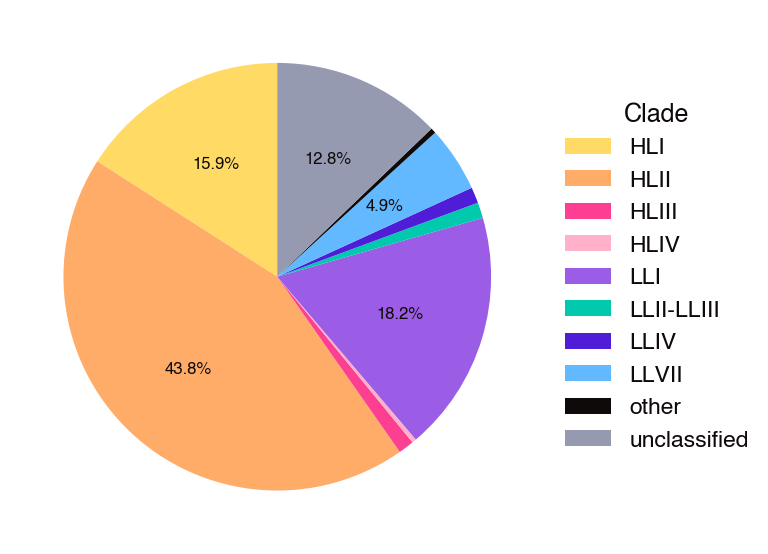

In [8]:
# make pie chart of global relative abundances by clade

# simplify some categories for better visualization
plot_df = pro_global_rel_abund_df.copy()
plot_df.loc[plot_df['clade'].isin(['AMZ-I', 'HLVI', 'LLVIII', 'HLII-HLVI', 'AMZ-III']), 'clade'] = 'other'
plot_df = plot_df.groupby('clade')['global_rel_abundance'].sum().reset_index()

# map clades to colors
clade_color_mapping = {
    'HLI': accent_colors[6],
    'HLII': accent_colors[1],
    'HLIII': accent_colors[3],
    'HLIV': accent_colors[8],
    'LLI': accent_colors[0],
    'LLII-LLIII': accent_colors[2],
    'LLIV': accent_colors[9],
    'LLVII': accent_colors[7],
    'other': accent_colors[4], 
    'unclassified': accent_colors[5],
}

# build figure with legends, and only label percentage for clades with >3% global relative abundance
plt.figure(figsize=(8, 8))
plt.pie(
    plot_df['global_rel_abundance'],
    autopct=lambda p: '{:.1f}%'.format(p) if p > 3 else '',
    startangle=90,
    colors=[clade_color_mapping[clade] for clade in plot_df['clade']],
    textprops={'fontsize': 12}
)

plt.legend(title='Clade', loc='center left', bbox_to_anchor=(1, 0.5), labels=plot_df['clade'])
# # move title right to center combined pie chart ane legend area
# plt.title('Global Prochlorococcus Relative Abundance by Clade', loc='left')
plt.tight_layout()
plt.show()

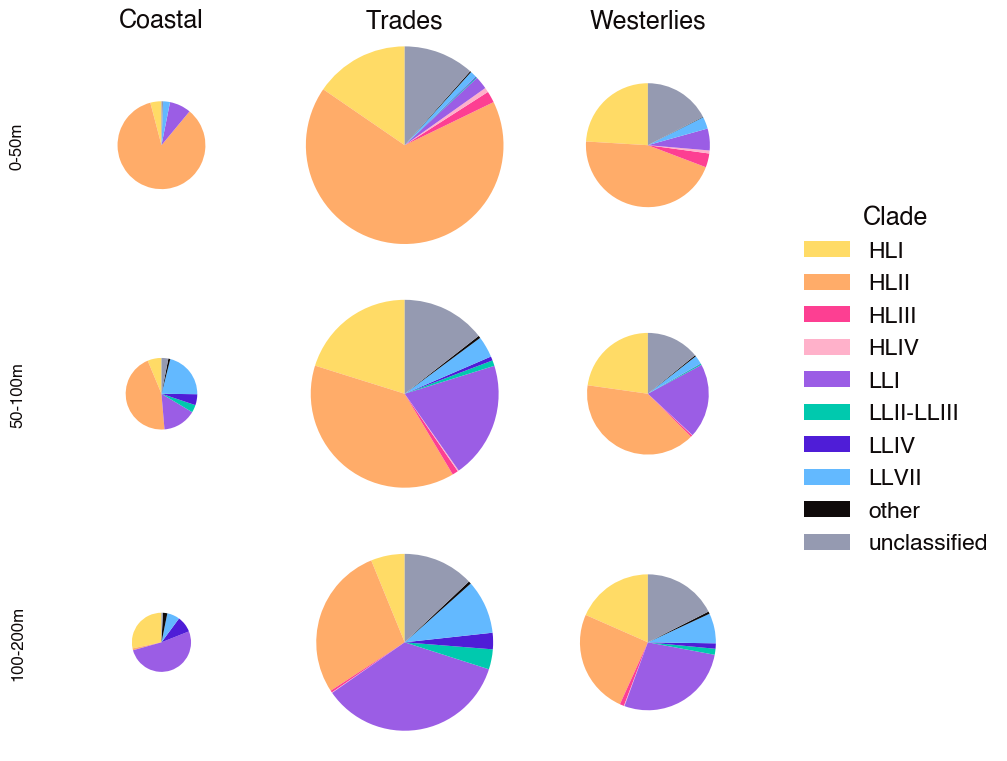

In [9]:
# scaled pie chart of global relative abundances by biome-depth bin

def scaled_pie(ax, values, area_scale=1, colors=None):
    values = np.asarray(values, dtype=float)
    fracs = values / values.sum()

    radius = np.sqrt(area_scale)
    start = 90

    if colors is None:
        colors = plt.cm.tab20(np.linspace(0, 1, len(values)))

    for frac, color in zip(fracs, colors):
        theta = frac * 360
        wedge = Wedge(
            center=(0, 0),
            r=radius,
            theta1=start,
            theta2=start + theta,
            facecolor=color,
            edgecolor="white"
        )
        ax.add_patch(wedge)
        start += theta

    ax.set_aspect("equal")
    ax.set_xlim(-1.1 * max_radius, 1.1 * max_radius)
    ax.set_ylim(-1.1 * max_radius, 1.1 * max_radius)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

# find maximum radius for scaling pies
max_radius = np.sqrt(pro_factors_df.max().max())

# make figure
fig, axes = plt.subplots(3, 3, figsize=(8, 8))

# plot each bin as a separate scaled pie
for i, biome in enumerate(['Coastal', 'Trades', 'Westerlies']):
    for j, depth_bin in enumerate(['0-50m', '50-100m', '100-200m']):
        # filter the data for the current biome and depth bin
        plot_df = pro_rel_abund_df[
            (pro_rel_abund_df['biome'] == biome) &
            (pro_rel_abund_df['depth_bin'] == depth_bin)
        ]
        plot_df.loc[plot_df['clade'].isin(
            ['AMZ-I', 'HLVI', 'LLVIII', 'HLII-HLVI', 'AMZ-III']), 'clade'] = 'other'
        plot_df = plot_df.groupby('clade')['rel_abundance'].sum().reset_index()
        # add color mapping
        plot_df['color'] = plot_df['clade'].map(clade_color_mapping)
        # sort by clade name
        plot_df = plot_df.sort_values('clade')
        # pull out multiplication factor
        factor = pro_factors_df.loc[biome, depth_bin]

        # plot pie
        scaled_pie(axes[j][i], plot_df['rel_abundance'], area_scale=factor, colors=plot_df['color'])

        # label rows and columns
        if i == 0:
            axes[j][i].set_ylabel(
                depth_bin, 
                fontsize=12,
                rotation=90,
                labelpad=20
                )
        if j == 0:
            axes[j][i].set_title(biome)

# figure-level legend
legend_handles = [
    Patch(facecolor=color, label=label)
    for label, color in zip(clade_color_mapping.keys(), clade_color_mapping.values())
]
fig.legend(
    handles=legend_handles,
    title="Clade",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
)

plt.tight_layout()
plt.show()

# Per-clade gene prevalences
Calculate gene prevalence values for each clade subpopulation

In [10]:
# Read in the full presence/absence data

# directory paths
data_dir = project_root / "data"

# presence/absence data
pa_df = pd.read_csv(
    data_dir / "pro_pangenome_presence_absence_data.csv",
    index_col=0,
).T

# metadata for the genomes in the clade-balanced dataset
genome_metadata_df = pd.read_csv(data_dir / "pro_pangenome_metadata.csv")
completeness_series = genome_metadata_df.set_index("genome")["completeness"] / 100

pa_df

gene_cluster_id,GC_00000001,GC_00000002,GC_00000003,GC_00000004,GC_00000005,GC_00000006,GC_00000007,GC_00000008,GC_00000009,GC_00000010,...,GC_00052849,GC_00052850,GC_00052851,GC_00052852,GC_00052853,GC_00052854,GC_00052855,GC_00052856,GC_00052857,GC_00052858
ProchlorococcusAC669I9,0,1,1,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAC669J22,1,1,1,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAC669O11,0,1,1,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAC669K21,1,1,1,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAC669K20,1,1,0,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ProchlorococcusMIT1223,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAG402N21,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAG409P19,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAG409D09,1,1,1,1,1,0,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0


In [11]:
# mark how many reference genomes per clade
# NOTE: we'll use all reference genomes for the "unclassified" subpopulation

# count the number of reference genomes per clade
pro_global_rel_abund_df['n_ref_genomes'] = pro_global_rel_abund_df.clade.map(
    genome_metadata_df.clade.value_counts()).fillna(0).astype(int)
print(f"Total utilized reference genomes: {pro_global_rel_abund_df['n_ref_genomes'].sum()}")

# update the number of reference genomes for the "unclassified" clade
pro_global_rel_abund_df.loc[
    pro_global_rel_abund_df.clade == "unclassified", 'n_ref_genomes'] = genome_metadata_df.shape[0]

# identify unused reference genomes
print("Unused reference genomes:")
print(genome_metadata_df.clade.value_counts().loc[
    [i for i in genome_metadata_df.clade.value_counts().index if i not in pro_global_rel_abund_df.clade.values]])

pro_global_rel_abund_df

Total utilized reference genomes: 1024
Unused reference genomes:
clade
AMZ-III    43
AMZ-II     32
Name: count, dtype: int64


,clade,global_rel_abundance,n_ref_genomes
0,HLII,0.437893,517
1,LLI,0.182105,122
2,HLI,0.159247,146
3,unclassified,0.128252,1099
4,LLVII,0.049486,64
5,LLIV,0.012021,30
6,LLII-LLIII,0.011924,39
7,HLIII,0.011823,9
8,HLIV,0.003265,30
9,HLVI,0.002440,12


In [12]:
# fit the MLE model to each clade subset separately and save the outputs

# initiate dictionary for model results
model_results = {}

# initiate dataframe for comparing prevalence estimates and core size across clades
prevalence_df = pd.DataFrame(index=pa_df.columns)
gene_categories_df = pd.DataFrame(index=['core', 'extended core', 'shell', 'cloud', 'core_ci'])

# make directory to save fit dataframes
outdir = data_dir / "outputs"  
outdir.mkdir(parents=True, exist_ok=True)

# iterate over each clade
clades = list(pro_global_rel_abund_df.clade.unique()) + ['AMZ-II', 'AMZ-III'] # include AMZ clades for supplemental material
for clade in clades:
    
    # pull out the reference genomes for the current clade
    if clade == "unclassified":
        genome_subset = genome_metadata_df.loc[:, 'genome'] # select all the genomes
    else:
        genome_subset = genome_metadata_df.loc[genome_metadata_df.clade == clade, 'genome']
    subset_pa_df = pa_df.loc[genome_subset]
    print(f"\nFitting model for clade {clade} with {len(genome_subset)} genomes.")

    # fit prevalence model to the subset
    model = BernoulliPrevalenceModel(
        data=subset_pa_df, 
        lambdas=completeness_series.loc[genome_subset], 
    )
    fit = model.fit(
        estimator="mle",
        interval_method="likelihood_ratio",
        alpha=ci_alpha,
        clip=True,
    )

    # save the fit result for the current clade
    model_results[clade] = fit

    # make dataframe of prevalence estimates for current clade
    fit_df = pd.DataFrame({
        'prevalence': fit.prevalence, 
        f'{(1-ci_alpha)*100:.0f}%_ci_lower': fit.ci_lower, 
        f'{(1-ci_alpha)*100:.0f}%_ci_upper': fit.ci_upper}).reset_index()
    
    # set gene category based on prevalence
    conditions = [
        fit_df["prevalence"] == 0,
        fit_df["prevalence"] == 1.0,
        fit_df["prevalence"] >= 0.9,
        fit_df["prevalence"] > 0.15,
    ]
    choices = ["", "core", "extended core", "shell"]
    fit_df['gene_category'] = np.select(conditions, choices, default="cloud")
    counts_df = fit_df.gene_category.value_counts().reindex(
        ["core", "extended core", "shell", "cloud"], fill_value=0)
    print(f"Total detected genes: {counts_df.sum()}")
    print(f"Total extended core: {counts_df.get('extended core', 0) + counts_df.get('core', 0)}")
    print(f"Total extended core + shell: {counts_df.get('extended core', 0) + counts_df.get('core', 0) + counts_df.get('shell', 0)}")
    counts_df['core_ci'] = fit_df[f'{(1-ci_alpha)*100:.0f}%_ci_upper'].eq(1).sum()
    print(counts_df)
    
    # save dataframe of prevalence estimates for current clade
    if clade != 'unclassified':
        # save csv
        save_df = fit_df.copy()
        # re-define core genes as those with 95% CI that includes prevalence of 1
        save_df['gene_category'] = np.where(
            save_df[f'{(1-ci_alpha)*100:.0f}%_ci_upper'].eq(1),
            'core',
            save_df['gene_category']
        )
        save_df.to_csv(outdir / f"gene_prevalence_{clade}.csv", index=False)

        # save to the combined prevalence dataframe
        prevalence_df = prevalence_df.merge(
            fit_df.rename(columns={
                'prevalence': f'{clade}_prevalence', 
                f'{(1-ci_alpha)*100:.0f}%_ci_lower': f'{clade}_ci_lower',
                f'{(1-ci_alpha)*100:.0f}%_ci_upper': f'{clade}_ci_upper'
            }).set_index('gene_cluster_id').drop(columns='gene_category'),
            on='gene_cluster_id',
            how='left'
        )

        # save counts for the current clade
        gene_categories_df[clade] = counts_df

prevalence_df


Fitting model for clade HLII with 517 genomes.
Total detected genes: 15055
Total extended core: 1491
Total extended core + shell: 1943
gene_category
core               610
extended core      881
shell              452
cloud            13112
core_ci           1113
Name: count, dtype: int64

Fitting model for clade LLI with 122 genomes.
Total detected genes: 8231
Total extended core: 1613
Total extended core + shell: 2203
gene_category
core              962
extended core     651
shell             590
cloud            6028
core_ci          1536
Name: count, dtype: int64

Fitting model for clade HLI with 146 genomes.
Total detected genes: 7172
Total extended core: 1357
Total extended core + shell: 1969
gene_category
core              887
extended core     470
shell             612
cloud            5203
core_ci          1303
Name: count, dtype: int64

Fitting model for clade unclassified with 1099 genomes.
Total detected genes: 52500
Total extended core: 930
Total extended core + shell: 24

,HLII_prevalence,HLII_ci_lower,HLII_ci_upper,LLI_prevalence,LLI_ci_lower,LLI_ci_upper,HLI_prevalence,HLI_ci_lower,HLI_ci_upper,LLVII_prevalence,...,LLVIII_ci_upper,HLII-HLVI_prevalence,HLII-HLVI_ci_lower,HLII-HLVI_ci_upper,AMZ-II_prevalence,AMZ-II_ci_lower,AMZ-II_ci_upper,AMZ-III_prevalence,AMZ-III_ci_lower,AMZ-III_ci_upper
gene_cluster_id,,,,,,,,,,,,,,,,,,,,,
GC_00000001,1.0,0.995276,1.000000,1.0,0.982628,1.000000,1.0,0.983973,1.000000,1.000000,...,1.000000,1.0,0.382753,1.000000,1.0,0.875594,1.000000,0.0,0.000000,0.161732
GC_00000002,1.0,0.995566,1.000000,1.0,0.980233,1.000000,1.0,0.980398,1.000000,1.000000,...,1.000000,1.0,0.382753,1.000000,1.0,0.882706,1.000000,1.0,0.915973,1.000000
GC_00000003,1.0,0.995513,1.000000,1.0,0.978701,1.000000,1.0,0.982274,1.000000,1.000000,...,1.000000,1.0,0.382753,1.000000,1.0,0.861181,1.000000,1.0,0.901318,1.000000
GC_00000004,1.0,0.990299,1.000000,1.0,0.978236,1.000000,1.0,0.973813,1.000000,1.000000,...,1.000000,1.0,0.382753,1.000000,1.0,0.826343,1.000000,1.0,0.809259,1.000000
GC_00000005,1.0,0.994106,1.000000,1.0,0.977709,1.000000,1.0,0.980769,1.000000,1.000000,...,1.000000,1.0,0.382753,1.000000,1.0,0.873756,1.000000,1.0,0.895472,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GC_00052854,0.0,0.000000,0.005864,0.0,0.000000,0.026791,0.0,0.000000,0.025891,0.025357,...,0.429745,0.0,0.000000,0.815204,0.0,0.000000,0.187756,0.0,0.000000,0.161732
GC_00052855,0.0,0.000000,0.005864,0.0,0.000000,0.026791,0.0,0.000000,0.025891,0.025421,...,0.429745,0.0,0.000000,0.815204,0.0,0.000000,0.187756,0.0,0.000000,0.161732
GC_00052856,0.0,0.000000,0.005864,0.0,0.000000,0.026791,0.0,0.000000,0.025891,0.025339,...,0.429745,0.0,0.000000,0.815204,0.0,0.000000,0.187756,0.0,0.000000,0.161732


# Global Prochlorococcus gene prevalence
Aggregate clade subpopulation estimates for global gene prevalence estimates

In [13]:
# get majority KEGG annotation for gene clusters (for supplementary data table)

pan_db_path = data_dir / 'inputs/propan-PAN.db'
func_db_path = data_dir / 'inputs/propan-GENOMES.db'

pan_query = '''
SELECT
  gene_caller_id, 
  gene_cluster_id,
  genome_name
FROM gene_clusters
'''.strip()

func_query = '''
SELECT
  gene_callers_id AS gene_caller_id,
  source, 
  accession, 
  function
FROM gene_function_calls
WHERE source = "KEGG"
'''

with sqlite3.connect(pan_db_path) as conn:
    pan_df = pd.read_sql_query(pan_query, conn)

with sqlite3.connect(func_db_path) as conn:
    func_df = pd.read_sql_query(func_query, conn)

# add annotation onto pan_df
pan_df['accession'] = pan_df.gene_caller_id.map(
    func_df.set_index('gene_caller_id')['accession'])

# build cluster dataframe
cluster_df = pan_df.groupby('gene_cluster_id').gene_caller_id.count().reset_index(name='cluster_size')

# find majority annotation for each gene cluster, where a majority means that 
# at least half of the genes in that cluster are annotated with the same KEGG accession
annot_counts_df = pan_df.groupby('gene_cluster_id')['accession'].value_counts().reset_index(
    name='count')
annot_counts_df['majority_threshold'] = annot_counts_df['gene_cluster_id'].map(
    cluster_df.set_index('gene_cluster_id')['cluster_size'] // 2 + 1)

# filter for annotations that meet the majority threshold and add these back onto cluster_df
cluster_df['KEGG_accession'] = cluster_df['gene_cluster_id'].map(
    annot_counts_df[annot_counts_df['count'] >= annot_counts_df['majority_threshold']].set_index(
        'gene_cluster_id')['accession'])

# add function annotation for the majority KEGG accession
accession_to_func = (
    func_df[['accession', 'function']]
    .assign(func_len=lambda d: d['function'].str.len())
    .sort_values('func_len')
    .drop_duplicates(subset='accession', keep='first')
    .set_index('accession')['function']
)
cluster_df['KEGG_function'] = cluster_df['KEGG_accession'].map(accession_to_func)

cluster_df

,gene_cluster_id,cluster_size,KEGG_accession,KEGG_function
0,GC_00000001,5123,NaN,NaN
1,GC_00000002,2055,K01358,"ATP-dependent Clp protease, protease subunit [..."
2,GC_00000003,2012,K03798,cell division protease FtsH [EC:3.4.24.-]
3,GC_00000004,1865,NaN,NaN
4,GC_00000005,1584,K02469,DNA gyrase subunit A [EC:5.6.2.2]
...,...,...,...,...
52853,GC_00052854,1,NaN,NaN
52854,GC_00052855,1,NaN,NaN
52855,GC_00052856,1,NaN,NaN
52856,GC_00052857,1,NaN,NaN


In [14]:
# aggregate prevalence estimates across clades

# combine prevalence estimates across clades using the global relative abundances as weights
global_prevalence_results = combine_approx_var_likelihood(
    results=[model_results[clade] for clade in pro_global_rel_abund_df['clade']],
    proportions=pro_global_rel_abund_df['global_rel_abundance'],
    clip=True)

# # drop unclassified clade from the subset, and rescale proportions
# # NOTE: this is equivalent to assuming that the unclassified ASVs are proportionally
# # distributed across the classified clades
# subset_rel_abun_df = pro_global_rel_abund_df.copy().set_index('clade')
# subset_rel_abun_df = subset_rel_abun_df[~subset_rel_abun_df.index.isin(['unclassified'])]
# subset_rel_abun_df['global_rel_abundance'] = subset_rel_abun_df['global_rel_abundance'] / subset_rel_abun_df['global_rel_abundance'].sum()

# # combine prevalence estimates across clades using the global relative abundances as weights
# global_prevalence_results = combine_approx_var_likelihood(
#     results=[model_results[clade] for clade in subset_rel_abun_df.index],
#     proportions=subset_rel_abun_df['global_rel_abundance'],
#     clip=True)

# build dataframe of results
global_prevalence_df = pd.DataFrame({
    'prevalence': global_prevalence_results.prevalence, 
    f'{(1-ci_alpha)*100:.0f}%_ci_lower': global_prevalence_results.ci_lower, 
    f'{(1-ci_alpha)*100:.0f}%_ci_upper': global_prevalence_results.ci_upper
}).reset_index()
conditions = [
        global_prevalence_df["prevalence"] == 0,
        global_prevalence_df["prevalence"] == 1.0,
        global_prevalence_df["prevalence"] >= 0.9,
        global_prevalence_df["prevalence"] > 0.15,
        ]
choices = ["", "core", "extended core", "shell"]
global_prevalence_df['gene_category'] = np.select(conditions, choices, default="cloud")
global_prevalence_df['alt_gene_category'] = global_prevalence_df['gene_category']
global_prevalence_df.loc[global_prevalence_df[f'{(1-ci_alpha)*100:.0f}%_ci_upper'].eq(1), 'alt_gene_category'] = 'core'
counts_df = global_prevalence_df.gene_category.value_counts().reindex(
        ["core", "extended core", "shell", "cloud"], fill_value=0)
print(f"Total detected genes: {counts_df.sum()}")
print(f"Total extended core: {counts_df.get('extended core', 0) + counts_df.get('core', 0)}")
print(f"Total extended core + shell: {counts_df.get('extended core', 0) + counts_df.get('core', 0) + counts_df.get('shell', 0)}")
counts_df['core_ci'] = global_prevalence_df[f'{(1-ci_alpha)*100:.0f}%_ci_upper'].eq(1).sum()
print(counts_df)

# add counts_df to gene_categories_df
gene_categories_df['global_pro'] = counts_df

# add global prevalence information to prevalence_df
prevalence_df['global_pro_prevalence'] = global_prevalence_df.set_index('gene_cluster_id')['prevalence']
prevalence_df['global_pro_ci_lower'] = global_prevalence_df.set_index('gene_cluster_id')['95%_ci_lower']
prevalence_df['global_pro_ci_upper'] = global_prevalence_df.set_index('gene_cluster_id')['95%_ci_upper']

# add KEGG function annotation for the majority KEGG accession
global_prevalence_df = global_prevalence_df.merge(
    cluster_df[['gene_cluster_id', 'KEGG_accession', 'KEGG_function']],
    on='gene_cluster_id',
    how='left'
)

# save dataframe as csv
save_df = global_prevalence_df.drop(columns='gene_category').copy()
save_df = save_df.rename(columns={'alt_gene_category': 'gene_category'})
save_df.to_csv(outdir / 'pro_global_gene_prevalence.csv', index=False)

global_prevalence_df

Total detected genes: 52500
Total extended core: 964
Total extended core + shell: 2672
gene_category
core                27
extended core      937
shell             1708
cloud            49828
core_ci            714
Name: count, dtype: int64


,gene_cluster_id,prevalence,95%_ci_lower,95%_ci_upper,gene_category,alt_gene_category,KEGG_accession,KEGG_function
0,GC_00000001,0.999974,0.996926,1.000000,extended core,core,NaN,NaN
1,GC_00000002,1.000000,0.996893,1.000000,core,core,K01358,"ATP-dependent Clp protease, protease subunit [..."
2,GC_00000003,1.000000,0.996907,1.000000,core,core,K03798,cell division protease FtsH [EC:3.4.24.-]
3,GC_00000004,1.000000,0.995387,1.000000,core,core,NaN,NaN
4,GC_00000005,1.000000,0.996572,1.000000,core,core,K02469,DNA gyrase subunit A [EC:5.6.2.2]
...,...,...,...,...,...,...,...,...
52495,GC_00052854,0.001456,0.000000,0.006468,cloud,cloud,NaN,NaN
52496,GC_00052855,0.001459,0.000000,0.006475,cloud,cloud,NaN,NaN
52497,GC_00052856,0.001455,0.000000,0.006466,cloud,cloud,NaN,NaN
52498,GC_00052857,0.001456,0.000000,0.006467,cloud,cloud,NaN,NaN


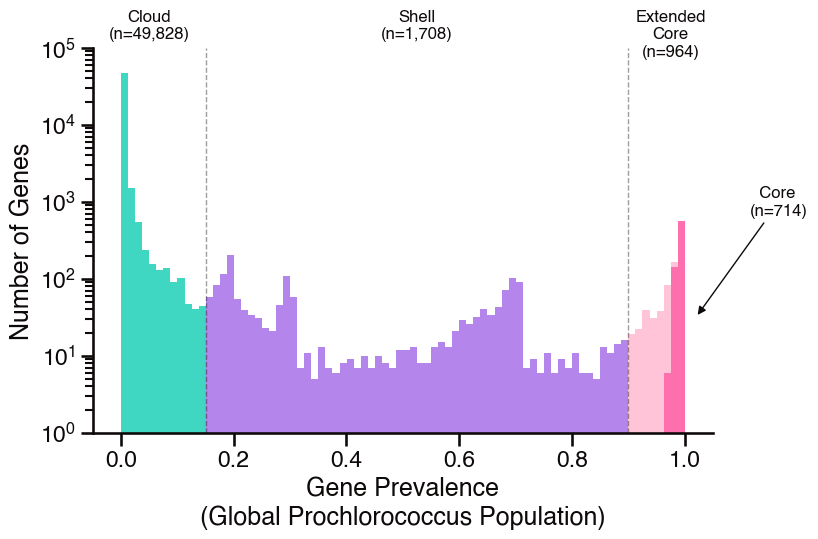

In [15]:
# look at distribution of global Pro gene prevalence values

# set category colors for gene prevalence visualization
gene_category_colors = {
    'core': accent_colors[3],
    'extended core': accent_colors[8],
    'shell': accent_colors[0],
    'cloud': accent_colors[2],
}
# gene_category_colors = {
#     'core': '#23104B',
#     'extended core': '#596BEB',
#     'shell': '#90B5EF',
#     'cloud': '#C1D7E8',
# }
category_order = ['cloud', 'shell', 'extended core', 'core']
cat_col = 'alt_gene_category'

# build figure
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(
    data=global_prevalence_df,
    x='prevalence',
    hue=cat_col,
    hue_order=category_order,
    palette=gene_category_colors,
    multiple='stack',
    bins=80,
    kde=False,
    legend=False,
    ax=ax,
)
ax.set_yscale('log')
ax.set_ylim(1, 1.001e5)
ax.set_xlabel('Gene Prevalence\n(Global Prochlorococcus Population)')
ax.set_ylabel('Number of Genes')

# mark category thresholds (0 and 1.0 boundaries coincide with the plot edges)
for threshold in [0.15, 0.9]:
    plt.axvline(threshold, color=line_color, linestyle='--', linewidth=1, alpha=0.4)

# annotate gene categories and sizes
regions = [
    ('cloud', -0.05, 0.15),
    ('shell', 0.15, 0.9),
    ('extended core', 0.9, 1.05),
]
for cat, xmin, xmax in regions:
    x_center = (xmin + xmax) / 2
    count = global_prevalence_df[cat_col].eq(cat).sum()
    if cat == 'extended core':
        count += global_prevalence_df[cat_col].eq('core').sum()
        cat = 'Extended\nCore'
    else:
        cat = cat.capitalize()
    ax.text(
        x_center, 1.1, f'{cat}\n(n={count:,})',ha='center', va='top', fontsize=12,
        transform=ax.get_xaxis_transform(), clip_on=False,
    )

# annotate core genes with arrow
ax.annotate(
    f"  Core\n(n={global_prevalence_df[cat_col].eq('core').sum()})",
    xy=(1.02, 0.3), xycoords=('data', 'axes fraction'),
    xytext=(1.06, 0.6), textcoords='axes fraction',
    ha='left', va='center', fontsize=12,
    arrowprops=dict(arrowstyle='-|>', color=line_color, lw=1),
    annotation_clip=False,
)

plt.show()


In [16]:
# update gene categories to use confidence intervals

gene_categories_df = gene_categories_df.T

gene_categories_df['total_extended_core'] = gene_categories_df['extended core'] + gene_categories_df['core']
gene_categories_df['total_extended_core+shell'] = gene_categories_df['total_extended_core'] + gene_categories_df['shell']
gene_categories_df['extended_core_ci'] = np.maximum(0, gene_categories_df['total_extended_core'] - gene_categories_df['core_ci'])
gene_categories_df['shell_ci'] = np.maximum(0, gene_categories_df['total_extended_core+shell'] - gene_categories_df['core_ci'])

gene_categories_df = gene_categories_df.T

gene_categories_df

,HLII,LLI,HLI,LLVII,LLIV,LLII-LLIII,HLIII,HLIV,HLVI,AMZ-I,LLVIII,HLII-HLVI,AMZ-II,AMZ-III,global_pro
core,610,962,887,832,1843,1173,832,753,1002,1130,852,931,1031,1378,27
extended core,881,651,470,336,136,155,167,418,221,233,311,0,216,215,937
shell,452,590,612,929,1280,876,1275,829,638,1992,1842,887,1750,2472,1708
cloud,13112,6028,5203,9489,2690,4161,0,1574,787,4562,0,0,1384,2101,49828
core_ci,1113,1536,1303,1209,1843,1310,1678,1583,1577,1928,1571,1818,2084,2604,714
total_extended_core,1491,1613,1357,1168,1979,1328,999,1171,1223,1363,1163,931,1247,1593,964
total_extended_core+shell,1943,2203,1969,2097,3259,2204,2274,2000,1861,3355,3005,1818,2997,4065,2672
extended_core_ci,378,77,54,0,136,18,0,0,0,0,0,0,0,0,250
shell_ci,830,667,666,888,1416,894,596,417,284,1427,1434,0,913,1461,1958


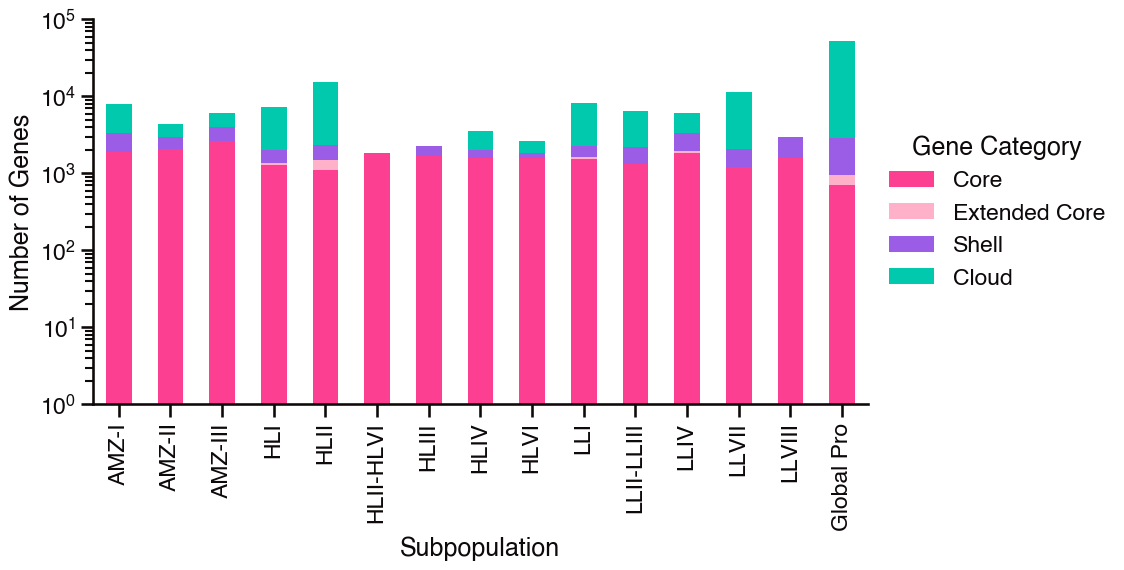

In [17]:
# look at composition of clade gene categories in comparison with global pro gene categories

# columns = {
#     'core': 'Core', 
#     'extended core': 'Extended Core', 
#     'shell': 'Shell', 
#     'cloud': 'Cloud'
# }
columns = {
    'core_ci': 'Core', 
    'extended_core_ci': 'Extended Core', 
    'shell_ci': 'Shell', 
    'cloud': 'Cloud'
}
plot_df = gene_categories_df.T[columns.keys()].sort_index()
plot_df = plot_df.rename(
    index={'global_pro': 'Global Pro'},
    columns=columns
)

fig, ax = plt.subplots(figsize=(10, 5))
plot_df.plot(
    kind='bar', 
    stacked=True,
    color=list(gene_category_colors.values()),
    ax=ax
)
ax.set_yscale('log')
ax.set_ylim(1, 1.001e5)
ax.set_xlabel('Subpopulation')
ax.set_ylabel('Number of Genes')
ax.legend(title='Gene Category', loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

,n_ref_genomes,core,extended core,shell,cloud,core_ci,total_extended_core,total_extended_core+shell,extended_core_ci,shell_ci,total_ext_core,core_95_ci,label
population,,,,,,,,,,,,,
HLII,517,610,881,452,13112,1113,1491,1943,378,830,1491,1113,HLII
LLI,122,962,651,590,6028,1536,1613,2203,77,667,1613,1536,LLI
HLI,146,887,470,612,5203,1303,1357,1969,54,666,1357,1303,HLI
global_pro,1099,27,937,1708,49828,714,964,2672,250,1958,964,714,Global Pro
LLVII,64,832,336,929,9489,1209,1168,2097,0,888,1168,1209,LLVII
LLIV,30,1843,136,1280,2690,1843,1979,3259,136,1416,1979,1843,LLIV
LLII-LLIII,39,1173,155,876,4161,1310,1328,2204,18,894,1328,1310,LLII-LLIII
HLIII,9,832,167,1275,0,1678,999,2274,0,596,999,1678,HLIII
HLIV,30,753,418,829,1574,1583,1171,2000,0,417,1171,1583,HLIV


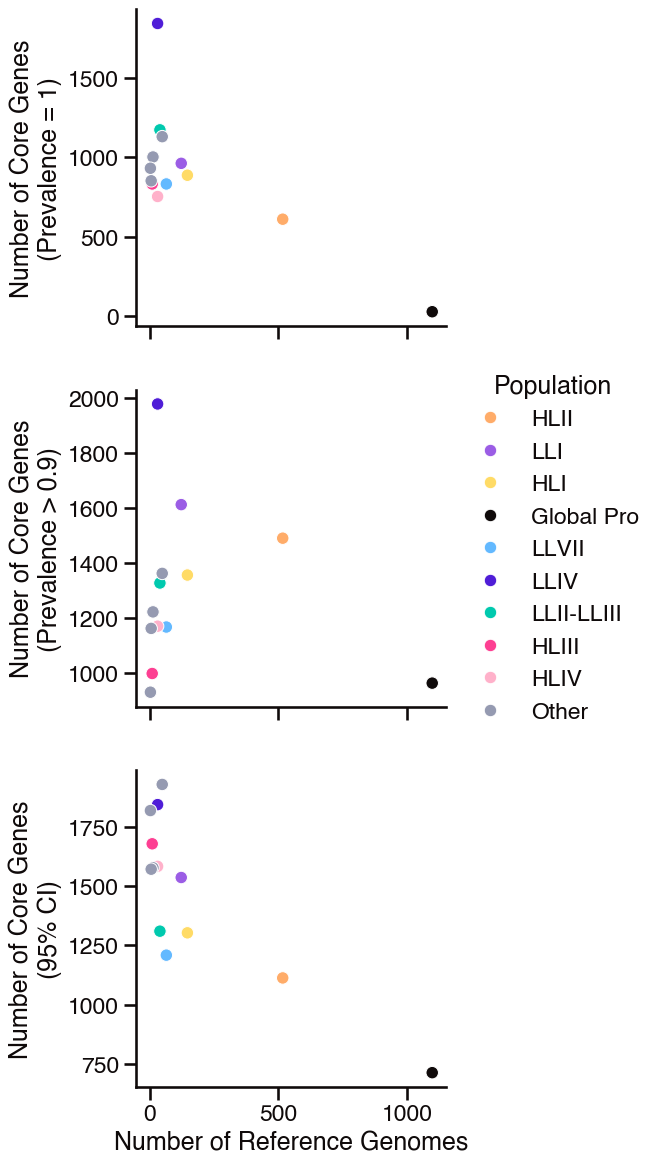

In [18]:
# look at how core size scales with number of reference genomes

core_size_df = pro_global_rel_abund_df.copy().drop(columns='global_rel_abundance')
core_size_df.loc[core_size_df.clade.eq('unclassified'), 'clade'] = 'global_pro'
core_size_df = core_size_df.rename(columns={'clade': 'population'})
core_size_df = core_size_df.set_index('population').merge(
    gene_categories_df.T, left_index=True, right_index=True, how='left')
core_size_df['total_ext_core'] = core_size_df['core'] + core_size_df['extended core']

# add 95% confidence interval definition of core
for pop in core_size_df.index:
    core_size = prevalence_df[f'{pop}_ci_upper'].eq(1).sum()
    core_size_df.loc[pop, 'core_95_ci'] = core_size
core_size_df['core_95_ci'] = core_size_df['core_95_ci'].astype(int)

# add labels (for plotting)
core_size_df['label'] = core_size_df.index
core_size_df.loc[['AMZ-I', 'HLVI', 'HLII-HLVI', 'LLVIII'], 'label'] = 'Other'
core_size_df.loc['global_pro', 'label'] = 'Global Pro'
display(core_size_df)

# fix colormap for this plot
clade_color_mapping['Global Pro'] = clade_color_mapping['other']
clade_color_mapping['Other'] = clade_color_mapping['unclassified']

# plot core size versus number of reference genomes
fig, axes = plt.subplots(3, 1, figsize=(4, 14), sharex=True)
x_labels = {'core': 'Prevalence = 1', 'total_ext_core': 'Prevalence > 0.9', 'core_95_ci': '95% CI'}
for i, xvar in enumerate(['core', 'total_ext_core', 'core_95_ci']):
    sns.scatterplot(
        data=core_size_df, 
        x='n_ref_genomes', 
        y=xvar, 
        hue='label',
        palette=clade_color_mapping, 
        ax=axes[i], 
        legend=(i==1)
        )
    axes[i].set_xlabel('Number of Reference Genomes')
    axes[i].set_ylabel(f'Number of Core Genes\n({x_labels[xvar]})')
    if i == 1:
        axes[i].legend(title='Population', loc='center left', bbox_to_anchor=(1, 0.5))

plt.show()

# Main figure
Make compound figure of clade composition and global gene prevalence

Text(1.06, 0.6, '  Core\n(n=714)')

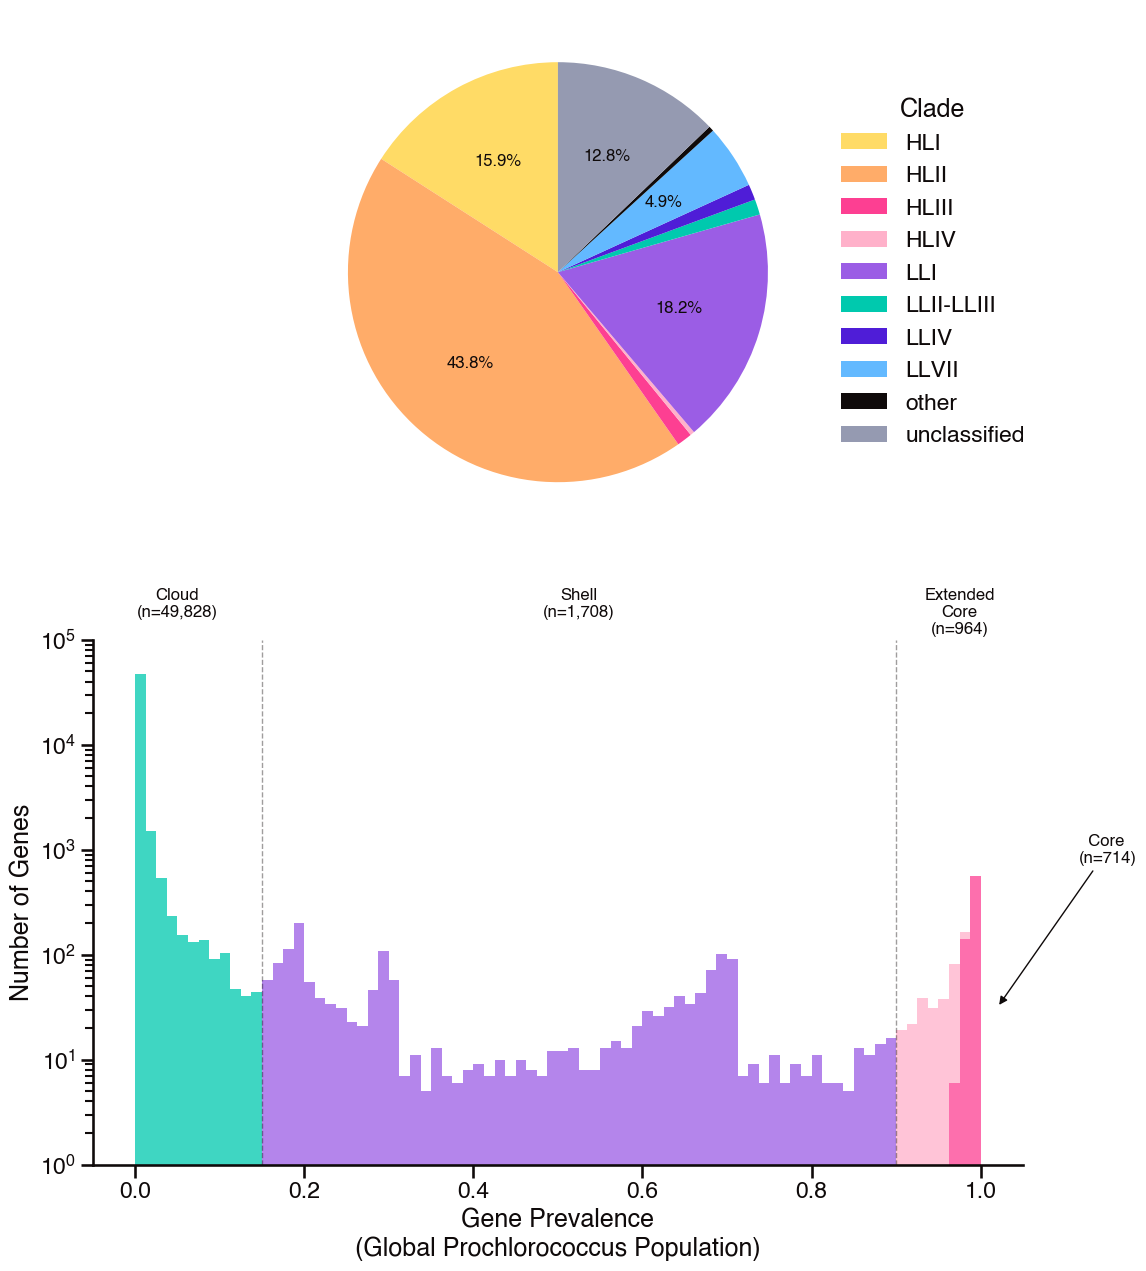

In [19]:
# make two panel figure with composition and gene prevalence

fig, axes = plt.subplots(2, 1, figsize=(12, 15))

# panel a: pie chart
plot_df = pro_global_rel_abund_df.copy()
plot_df.loc[plot_df['clade'].isin(['AMZ-I', 'HLVI', 'LLVIII', 'HLII-HLVI', 'AMZ-III']), 'clade'] = 'other'
plot_df = plot_df.groupby('clade')['global_rel_abundance'].sum().reset_index()

# build figure with legends, and only label percentage for clades with >3% global relative abundance
axes[0].pie(
    plot_df['global_rel_abundance'],
    autopct=lambda p: '{:.1f}%'.format(p) if p > 3 else '',
    startangle=90,
    colors=[clade_color_mapping[clade] for clade in plot_df['clade']],
    textprops={'fontsize': 12},
)

axes[0].legend(title='Clade', loc='center left', bbox_to_anchor=(1, 0.5), labels=plot_df['clade'])
# # move title right to center combined pie chart ane legend area
# axes[0].set_title('Global Prochlorococcus\nRelative Abundance by Clade', loc='center')

# panel b: histogram
sns.histplot(
    data=global_prevalence_df,
    x='prevalence',
    hue=cat_col,
    hue_order=category_order,
    palette=gene_category_colors,
    multiple='stack',
    bins=80,
    kde=False,
    legend=False,
    ax=axes[1],
)
axes[1].set_yscale('log')
axes[1].set_ylim(1, 1.001e5)
axes[1].set_xlabel('Gene Prevalence\n(Global Prochlorococcus Population)')
axes[1].set_ylabel('Number of Genes')

# mark category thresholds (0 and 1.0 boundaries coincide with the plot edges)
for threshold in [0.15, 0.9]:
    axes[1].axvline(threshold, color=line_color, linestyle='--', linewidth=1, alpha=0.4)

# annotate gene categories and sizes
regions = [
    ('cloud', -0.05, 0.15),
    ('shell', 0.15, 0.9),
    ('extended core', 0.9, 1.05),
]
for cat, xmin, xmax in regions:
    x_center = (xmin + xmax) / 2
    count = global_prevalence_df[cat_col].eq(cat).sum()
    if cat == 'extended core':
        count += global_prevalence_df[cat_col].eq('core').sum()
        cat = 'Extended\nCore'
    else:
        cat = cat.capitalize()
    axes[1].text(
        x_center, 1.1, f'{cat}\n(n={count:,})',ha='center', va='top', fontsize=12,
        transform=axes[1].get_xaxis_transform(), clip_on=False,
    )

# annotate core genes with arrow
axes[1].annotate(
    f"  Core\n(n={global_prevalence_df[cat_col].eq('core').sum()})",
    xy=(1.02, 0.3), xycoords=('data', 'axes fraction'),
    xytext=(1.06, 0.6), textcoords='axes fraction',
    ha='left', va='center', fontsize=12,
    arrowprops=dict(arrowstyle='-|>', color=line_color, lw=1),
    annotation_clip=False,
)
